## 1. Instalacja i import

In [ ]:
!pip -q install torch numpy matplotlib

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cuda


## 2. Dane: szereg czasowy

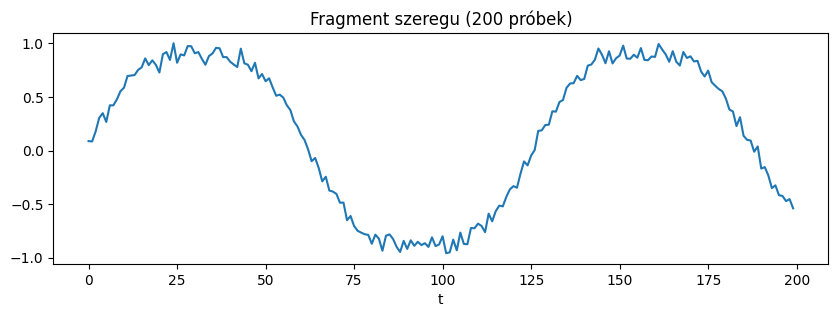

In [ ]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10,3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)'); plt.xlabel('t'); plt.show()

## 3. Okna wejście–cel

In [ ]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]     # [N, 1]
    return X, Y

OKNO = 30
X, Y = zrob_okna(seria, OKNO)

# Podział chronologiczny (bez tasowania — to szereg czasowy!)
n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


## 4. Model RNN

In [ ]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   # ostatni krok -> predykcja

## 5. Pętla uczenia

In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # anti-eksplozja
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
    return hist

model = ModelRNN(hidden=32, typ='RNN')
hist = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30)
print(f'Strata test: {hist[0]:.4f} -> {hist[-1]:.4f}')

Strata test: 0.0078 -> 0.0038


## 6. Krzywa uczenia

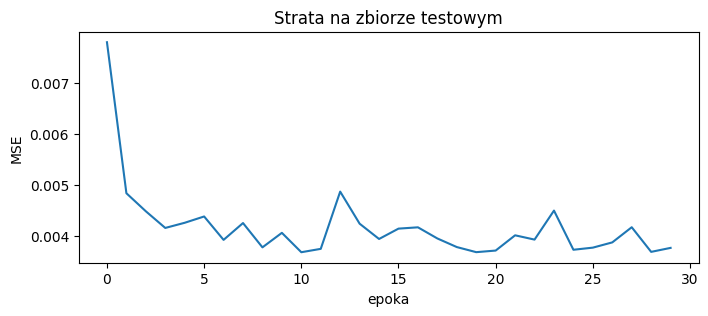

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(hist)
plt.title('Strata na zbiorze testowym'); plt.xlabel('epoka'); plt.ylabel('MSE'); plt.show()

## 7. Predykcja vs rzeczywistość

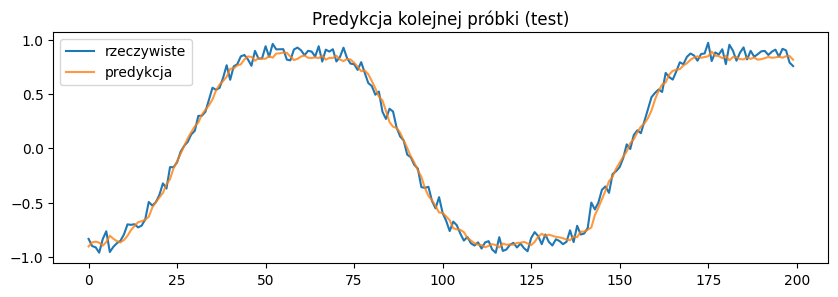

In [ ]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend(); plt.title('Predykcja kolejnej próbki (test)'); plt.show()

## 8. Eksperyment: typ komórki oraz liczba jednostek

Porównanie SimpleRNN/LSTM/GRU i wpływu rozmiaru stanu ukrytego.

In [ ]:
print('Typ komórki (hidden=32):')
for typ in ['RNN','LSTM','GRU']:
    h = trenuj(ModelRNN(hidden=32, typ=typ), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  {typ:5s} test MSE = {h[-1]:.4f}')

print('Liczba jednostek (GRU):')
for hs in [8, 32, 64]:
    h = trenuj(ModelRNN(hidden=hs, typ='GRU'), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  hidden={hs:3d} test MSE = {h[-1]:.4f}')

Typ komórki (hidden=32):
  RNN   test MSE = 0.0055
  LSTM  test MSE = 0.0036
  GRU   test MSE = 0.0035
Liczba jednostek (GRU):
  hidden=  8 test MSE = 0.0034
  hidden= 32 test MSE = 0.0038
  hidden= 64 test MSE = 0.0034


---
# Rozwiązanie Laboratorium 2 — kod i wyniki eksperymentów


## 9. Punkt 1 — punkt odniesienia

Pierwszy model `RNN`, `hidden=32`, `OKNO=30` został wytrenowany powyżej oryginalnym kodem z zajęć (`epoki=30`). Teraz zapisujemy jego wynik i porównujemy go z heurystyką „następna próbka = ostatnia próbka okna”.

In [ ]:
mse_bazowy = np.mean(hist[-5:])
mse_heurystyka = ((Yte - Xte[:, -1])**2).mean().item()

print(f'RNN, hidden=32, OKNO=30 — test MSE po ostatniej epoce: {hist[-1]:.6f}')
print(f'RNN, hidden=32, OKNO=30 — średnie test MSE z 5 ostatnich epok: {mse_bazowy:.6f}')
print(f'Heurystyka ostatniej próbki (OKNO=30) — test MSE: {mse_heurystyka:.6f}')

RNN, hidden=32, OKNO=30 — test MSE po ostatniej epoce: 0.003769
RNN, hidden=32, OKNO=30 — średnie test MSE z 5 ostatnich epok: 0.003857
Heurystyka ostatniej próbki (OKNO=30) — test MSE: 0.006309


### Uzupełnienie funkcji `trenuj` o stratę treningową

Dodajemy listę `hist_tr`. Od teraz funkcja zwraca dwie listy: `(hist, hist_tr)`, czyli stratę testową i treningową.

In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    hist_tr = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
            hist_tr.append(strata(model(Xtr), Ytr).item())
    return hist, hist_tr

## 10. Funkcje pomocnicze do eksperymentów

In [ ]:
import time

def przygotuj_dane(okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte


def heurystyka(okno):
    Xtr, Ytr, Xte, Yte = przygotuj_dane(okno)
    return ((Yte - Xte[:, -1])**2).mean().item()


def uruchom_konfiguracje(typ, hidden, okno):
    Xtr, Ytr, Xte, Yte = przygotuj_dane(okno)
    wyniki, czasy = [], []
    historie_test, historie_trening = [], []

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=hidden, typ=typ).to(DEVICE)
        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte,
                         epoki=20, lr=1e-2, batch=64)
        czasy.append(time.perf_counter() - t0)
        wyniki.append(np.mean(h[-5:]))
        historie_test.append(h)
        historie_trening.append(h_tr)
        if seed == 0:
            model_seed0 = model

    return {
        'typ': typ,
        'hidden': hidden,
        'okno': okno,
        'parametry': sum(p.numel() for p in model.parameters()),
        'mse': np.mean(wyniki),
        'odchylenie': np.std(wyniki),
        'czas': np.mean(czasy),
        'hist': np.mean(historie_test, axis=0),
        'hist_tr': np.mean(historie_trening, axis=0),
        'model_seed0': model_seed0
    }


def tabela_wynikow(wyniki):
    print(f'{"Konfiguracja":<26} {"Parametry":>10} {"Test MSE (średnia ± odch.)":>27} {"Czas [s]":>10}')
    print('-'*79)
    for okno in sorted(set(w['okno'] for w in wyniki)):
        print(f'{"Heurystyka, OKNO="+str(okno):<26} {0:>10} {heurystyka(okno):>27.6f} {"—":>10}')
    print('-'*79)
    for w in wyniki:
        nazwa = f"{w['typ']}, h={w['hidden']}, OKNO={w['okno']}"
        mse = f"{w['mse']:.6f} ± {w['odchylenie']:.6f}"
        print(f'{nazwa:<26} {w["parametry"]:>10} {mse:>27} {w["czas"]:>10.2f}')
    print('Czas to średni czas treningu z 3 ziaren (bez tworzenia danych).')


def wykres_test(wyniki, tytul):
    plt.figure(figsize=(10, 4))
    for w in wyniki:
        nazwa = f"{w['typ']}, h={w['hidden']}, OKNO={w['okno']}"
        plt.plot(range(1, 21), w['hist'], label=nazwa)
    plt.title(tytul)
    plt.xlabel('epoka')
    plt.ylabel('Test MSE')
    plt.legend()
    plt.grid(True)
    plt.show()

## 11. Eksperyment A — liczba jednostek ukrytych

Zmieniamy tylko `hidden = 8, 16, 32, 64`. Pozostaje `GRU`, `OKNO=30`, `epoki=20`, `lr=1e-2`, `batch=64`. Każdą konfigurację trenujemy dla ziaren 0, 1, 2.

Zakończono: GRU, hidden=8, OKNO=30
Zakończono: GRU, hidden=16, OKNO=30
Zakończono: GRU, hidden=32, OKNO=30
Zakończono: GRU, hidden=64, OKNO=30

TABELA — EKSPERYMENT A
Konfiguracja                Parametry  Test MSE (średnia ± odch.)   Czas [s]
-------------------------------------------------------------------------------
Heurystyka, OKNO=30                 0                    0.006309          —
-------------------------------------------------------------------------------
GRU, h=8, OKNO=30                 273         0.003797 ± 0.000045       1.55
GRU, h=16, OKNO=30                929         0.003737 ± 0.000021       1.19
GRU, h=32, OKNO=30               3393         0.003761 ± 0.000012       1.21
GRU, h=64, OKNO=30              12929         0.003751 ± 0.000082       1.29
Czas to średni czas treningu z 3 ziaren (bez tworzenia danych).


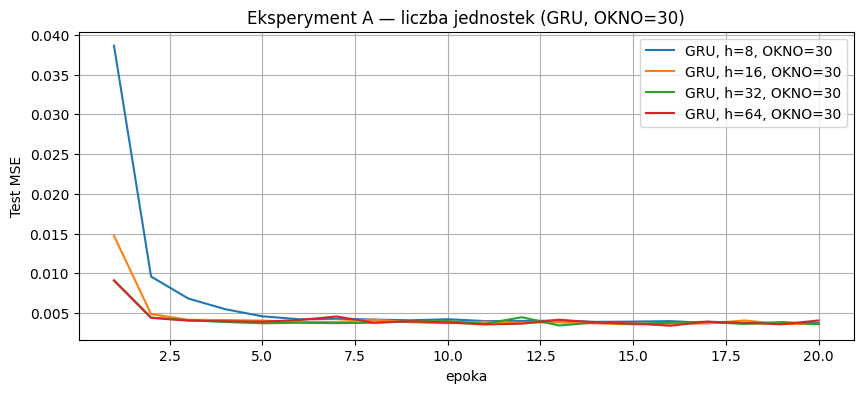

In [ ]:
wyniki_A = []
for hidden in [8, 16, 32, 64]:
    wynik = uruchom_konfiguracje('GRU', hidden, 30)
    wyniki_A.append(wynik)
    print(f'Zakończono: GRU, hidden={hidden}, OKNO=30')

print('\nTABELA — EKSPERYMENT A')
tabela_wynikow(wyniki_A)
wykres_test(wyniki_A, 'Eksperyment A — liczba jednostek (GRU, OKNO=30)')

## 12. Eksperyment B — długość okna

Zmieniamy tylko `OKNO = 10, 30, 60, 120`. Pozostaje `GRU`, `hidden=32`, `epoki=20`, `lr=1e-2`, `batch=64`. Funkcja `przygotuj_dane(okno)` tworzy nowy zestaw okien i ponownie dzieli dane dla **każdej** długości.

Zakończono: GRU, hidden=32, OKNO=10
Zakończono: GRU, hidden=32, OKNO=30
Zakończono: GRU, hidden=32, OKNO=60
Zakończono: GRU, hidden=32, OKNO=120

TABELA — EKSPERYMENT B
Konfiguracja                Parametry  Test MSE (średnia ± odch.)   Czas [s]
-------------------------------------------------------------------------------
Heurystyka, OKNO=10                 0                    0.006281          —
Heurystyka, OKNO=30                 0                    0.006309          —
Heurystyka, OKNO=60                 0                    0.006331          —
Heurystyka, OKNO=120                0                    0.006313          —
-------------------------------------------------------------------------------
GRU, h=32, OKNO=10               3393         0.004138 ± 0.000187       1.35
GRU, h=32, OKNO=30               3393         0.003761 ± 0.000012       1.20
GRU, h=32, OKNO=60               3393         0.003425 ± 0.000212       1.20
GRU, h=32, OKNO=120              3393         0.003437 

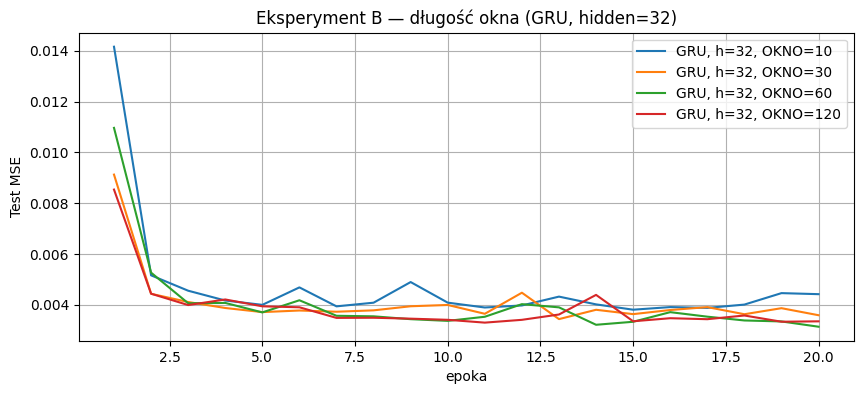

In [ ]:
wyniki_B = []
for okno in [10, 30, 60, 120]:
    wynik = uruchom_konfiguracje('GRU', 32, okno)
    wyniki_B.append(wynik)
    print(f'Zakończono: GRU, hidden=32, OKNO={okno}')

print('\nTABELA — EKSPERYMENT B')
tabela_wynikow(wyniki_B)
wykres_test(wyniki_B, 'Eksperyment B — długość okna (GRU, hidden=32)')

## 13. Eksperyment C — rodzaj komórki

Porównujemy `RNN`, `LSTM` i `GRU` przy `hidden=32` oraz dwóch długościach okna: `10` i `120`. Dla ustalonej długości zmienia się wyłącznie typ komórki. Pozostałe ustawienia pozostają identyczne.

Zakończono: RNN, hidden=32, OKNO=10
Zakończono: LSTM, hidden=32, OKNO=10
Zakończono: GRU, hidden=32, OKNO=10
Zakończono: RNN, hidden=32, OKNO=120
Zakończono: LSTM, hidden=32, OKNO=120
Zakończono: GRU, hidden=32, OKNO=120

TABELA — EKSPERYMENT C
Konfiguracja                Parametry  Test MSE (średnia ± odch.)   Czas [s]
-------------------------------------------------------------------------------
Heurystyka, OKNO=10                 0                    0.006281          —
Heurystyka, OKNO=120                0                    0.006313          —
-------------------------------------------------------------------------------
RNN, h=32, OKNO=10               1153         0.004171 ± 0.000246       1.10
LSTM, h=32, OKNO=10              4513         0.004151 ± 0.000112       1.24
GRU, h=32, OKNO=10               3393         0.004138 ± 0.000187       1.18
RNN, h=32, OKNO=120              1153         0.004003 ± 0.000008       1.08
LSTM, h=32, OKNO=120             4513         0.003748 ±

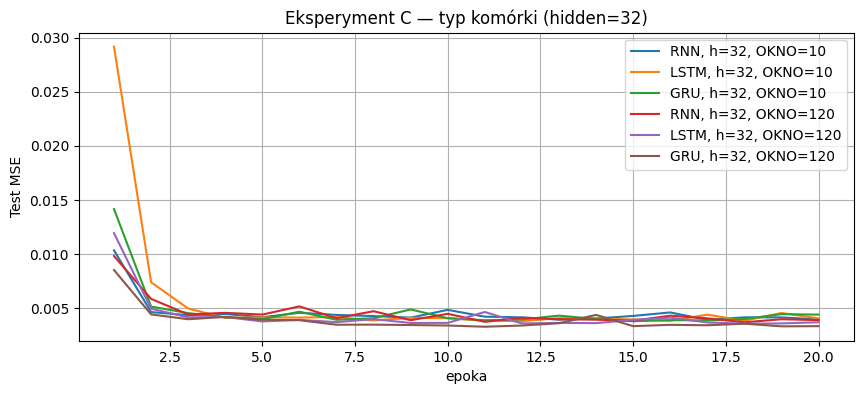

In [ ]:
wyniki_C = []
for okno in [10, 120]:
    for typ in ['RNN', 'LSTM', 'GRU']:
        wynik = uruchom_konfiguracje(typ, 32, okno)
        wyniki_C.append(wynik)
        print(f'Zakończono: {typ}, hidden=32, OKNO={okno}')

print('\nTABELA — EKSPERYMENT C')
tabela_wynikow(wyniki_C)
wykres_test(wyniki_C, 'Eksperyment C — typ komórki (hidden=32)')

## 14. Najlepsza konfiguracja — krzywe treningowe i predykcja

Wybieramy konfigurację o najniższej **średniej test MSE z trzech ziaren** (każda wartość obliczona jako `np.mean(hist[-5:])`). Krzywe uczenia poniżej są średnimi z trzech uruchomień. Do wykresu predykcji używamy wytrenowanego modelu z ziarnem 0 dla tej konfiguracji, czyli jednego rzeczywistego modelu, nie średniej predykcji trzech modeli.

Najlepszy: GRU, hidden=32, OKNO=60
Test MSE = 0.003425 ± 0.000212


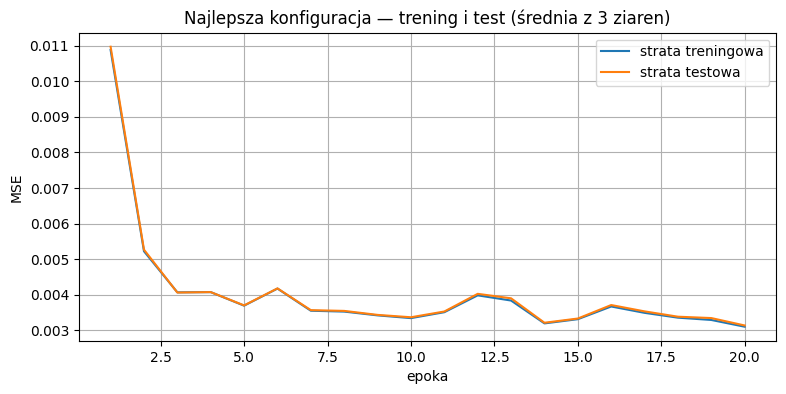

In [ ]:
wszystkie_wyniki = wyniki_A + wyniki_B + wyniki_C
najlepszy = min(wszystkie_wyniki, key=lambda w: w['mse'])

print(f"Najlepszy: {najlepszy['typ']}, hidden={najlepszy['hidden']}, OKNO={najlepszy['okno']}")
print(f"Test MSE = {najlepszy['mse']:.6f} ± {najlepszy['odchylenie']:.6f}")

plt.figure(figsize=(9, 4))
plt.plot(range(1, 21), najlepszy['hist_tr'], label='strata treningowa')
plt.plot(range(1, 21), najlepszy['hist'], label='strata testowa')
plt.xlabel('epoka')
plt.ylabel('MSE')
plt.title('Najlepsza konfiguracja — trening i test (średnia z 3 ziaren)')
plt.legend()
plt.grid(True)
plt.show()

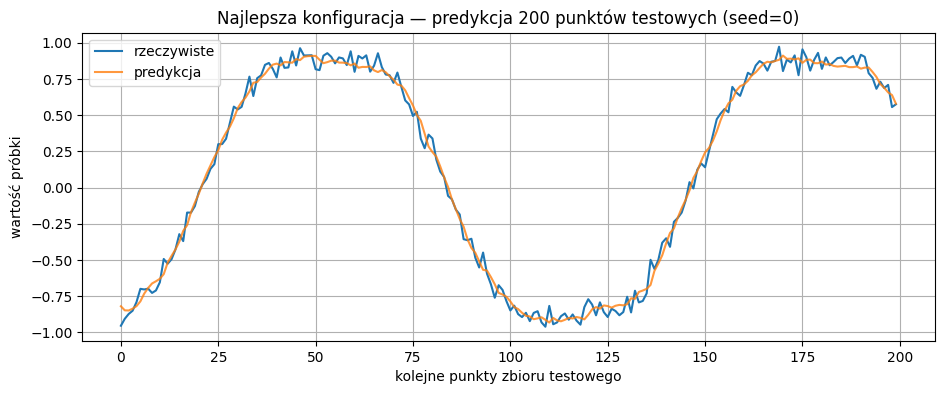

In [ ]:
Xtr_n, Ytr_n, Xte_n, Yte_n = przygotuj_dane(najlepszy['okno'])
model_n = najlepszy['model_seed0']
model_n.eval()
with torch.no_grad():
    pred = model_n(Xte_n).cpu().numpy().ravel()
prawdziwe = Yte_n.cpu().numpy().ravel()

plt.figure(figsize=(11, 4))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.xlabel('kolejne punkty zbioru testowego')
plt.ylabel('wartość próbki')
plt.title('Najlepsza konfiguracja — predykcja 200 punktów testowych (seed=0)')
plt.legend()
plt.grid(True)
plt.show()